# Explore the Data

## Import Libraries

In [1]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Load and Examine Data

In [2]:
data = pd.read_parquet("train_set.parquet")

data.head()

,year,phil_pred,max_temp_01_01,max_temp_01_02,max_temp_01_03,max_temp_01_04,max_temp_01_05,max_temp_01_06,max_temp_01_07,max_temp_01_08,...,max_soil_moisture_02_28,max_soil_moisture_02_29,max_soil_moisture_03_01,nino34_nov,nino34_dec,nino34_jan,nao_nov,nao_dec,nao_jan,early_spring
0,1963,False,21.0,26.0,33.0,35.0,41.0,36.0,36.0,34.0,...,0.456,NaN,0.455,-0.40,-0.32,-0.38,-0.23,-1.32,-2.1200,False
1,1982,False,42.0,37.0,39.0,53.0,35.0,47.0,40.0,26.0,...,0.474,NaN,0.497,-0.49,-0.07,0.32,-0.38,-0.02,-0.8900,True
2,1976,False,38.0,41.0,43.0,28.0,17.0,36.0,41.0,33.0,...,0.462,0.448,0.441,-0.79,-1.21,-1.34,0.41,0.00,-0.2500,False
3,2006,False,39.0,43.0,41.0,51.0,45.0,35.0,31.0,44.0,...,0.468,NaN,0.466,-0.50,-0.98,-0.94,-0.31,-0.44,1.2651,False
4,1953,False,34.0,42.0,42.0,33.0,28.0,28.0,31.0,37.0,...,0.483,NaN,0.465,-0.15,-0.40,0.86,-1.13,-0.43,0.3300,True


In [3]:
print("Number of observations: ", data.shape[0])
print("Number of columns: ", data.shape[1])

Number of observations:  57
Number of columns:  741


We have a very high-dimensional dataset: 57 samples (years) and 741 columns. One of those columns is the target (`early_spring`), so there are **740 predictors**: `year`, `phil_pred`, 732 daily weather/soil measurements (12 variables × 61 days from January 1 through March 1), and 6 monthly climate index values.

With roughly 13 predictors for every observation, there is a high risk of overfitting. A model could memorize patterns in the training years and struggle to generalize to new years.

In [4]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 57 entries, 0 to 56
Columns: 741 entries, year to early_spring
dtypes: bool(1), boolean(1), float64(738), int64(1)
memory usage: 329.4 KB


Our target variable is early_spring. Because it is Boolean, this is a binary classification problem. Our options are True: early spring, or False: not an early spring. Next we will examine the class distribution of the target variable.

In [5]:
data["early_spring"].value_counts()

early_spring
False    43
True     14
Name: count, dtype: int64

In [6]:
data["early_spring"].value_counts(normalize=True) * 100

early_spring
False    75.438596
True     24.561404
Name: proportion, dtype: float64

We see here that 75% of our observations are not early springs. This shows us that a model could predict false every single time and achieve 75% accuracy without being useful. Next we will visualize the target variable. 

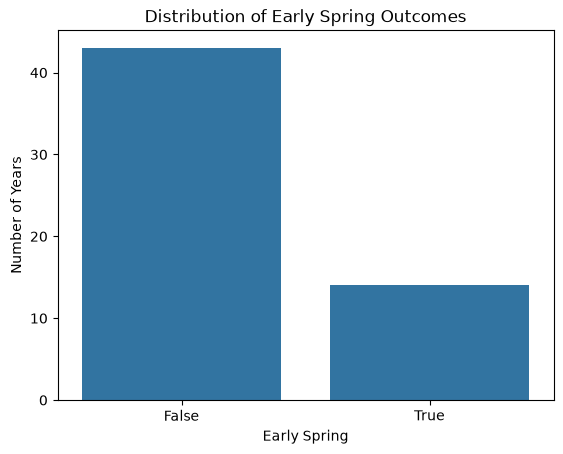

In [7]:
sns.countplot(data=data, x = "early_spring")

plt.title("Distribution of Early Spring Outcomes")
plt.xlabel("Early Spring")
plt.ylabel("Number of Years")

plt.show()

## Missing Data

In [8]:
missing_counts = data.isnull().sum()

missing_percentages = (
    missing_counts / len(data) * 100
)

missing_summary = pd.DataFrame({
    "Missing Count": missing_counts,
    "Missing Percentage": missing_percentages,
})

missing_summary = missing_summary[
    missing_summary["Missing Count"] > 0
].sort_values(
    by="Missing Percentage", 
    ascending=False
)

display(missing_summary.head(20))

print("Total missing values: ", data.isnull().sum().sum())
print("Columns with missing values: ", len(missing_summary))

,Missing Count,Missing Percentage
precipitation_02_29,42,73.684211
max_temp_02_29,42,73.684211
snowdepth_02_29,42,73.684211
snowfall_02_29,42,73.684211
avg_temp_02_29,42,73.684211
min_temp_02_29,42,73.684211
min_soil_moisture_02_29,41,71.929825
mean_soil_temp_02_29,41,71.929825
mean_soil_moisture_02_29,41,71.929825
min_soil_temp_02_29,41,71.929825


Total missing values:  894
Columns with missing values:  284


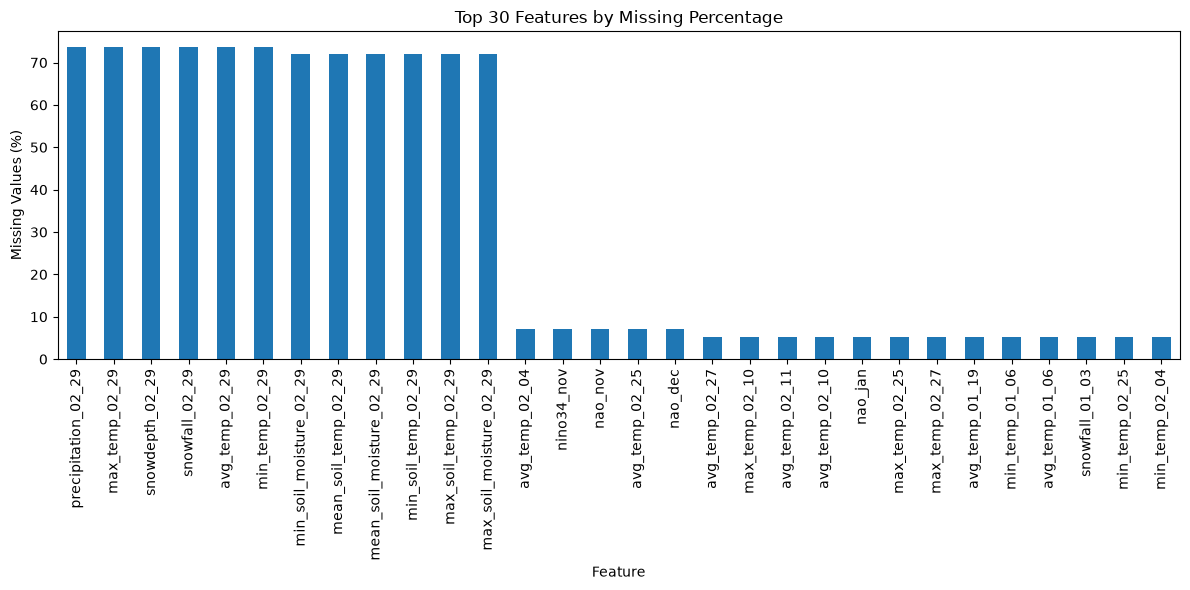

In [9]:
plt.figure(figsize=(12, 6))

missing_summary["Missing Percentage"].head(30).plot(
    kind="bar"
)

plt.title("Top 30 Features by Missing Percentage")
plt.xlabel("Feature")
plt.ylabel("Missing Values (%)")

plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

As expected, February 29 variables dominate this visualization. These features are missing for most years, which makes them a poor candidate for use. We may want to just remove these completely or handle leap days explicitly a different way. Removing this is reasonable because it will allow us to have consistent features across years. 

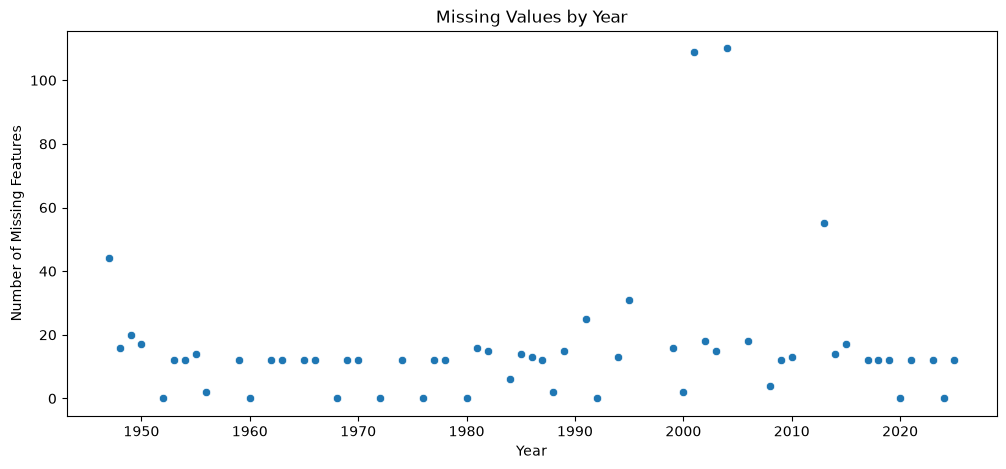

In [10]:
missing_by_year = data[["year"]].copy()

missing_by_year["missing_count"] = (
    data.isnull().sum(axis=1)
)

missing_by_year = missing_by_year.sort_values("year")

plt.figure(figsize=(12, 5))

sns.scatterplot(
    data=missing_by_year,
    x="year",
    y="missing_count"
)

plt.title("Missing Values by Year")
plt.xlabel("Year")
plt.ylabel("Number of Missing Features")

plt.show()

### Missing Value Findings

The dataset contains 894 missing values across 284 columns. A substantial portion of missingness is associated with February 29,
which only occurs during leap years. Removing February 29 columns is a potential preprocessing decision. Additional missing values occur in weather measurements and climate indices. These will require further investigation before choosing an imputation strategy.


In [11]:
duplicates = data.duplicated().sum()

duplicate_years = data["year"].duplicated().sum()

print("Duplicate rows:", duplicates)
print("Duplicate years:", duplicate_years)

Duplicate rows: 0
Duplicate years: 0


There are no duplicate rows and no duplicate years, so each observation represents a unique year.

In [12]:
constant_features = data.columns[data.nunique(dropna=True) <= 1]

print("Constant features:", len(constant_features))

Constant features: 0


In [13]:
display(data.describe().T)

,count,mean,std,min,25%,50%,75%,max
year,57.0,1986.105263,23.701028,1947.0000,1966.0000,1986.00000,2006.000000,2025.0000
max_temp_01_01,55.0,38.727273,12.477319,12.0000,31.5000,37.00000,45.000000,70.0000
max_temp_01_02,55.0,37.909091,10.333822,12.0000,31.5000,38.00000,44.000000,64.0000
max_temp_01_03,55.0,37.345455,10.543065,13.0000,31.5000,37.00000,43.500000,64.0000
max_temp_01_04,56.0,36.053571,11.837413,9.0000,30.0000,33.50000,42.000000,69.0000
...,...,...,...,...,...,...,...,...
nino34_dec,54.0,-0.048519,1.062788,-1.9400,-0.9800,-0.09000,0.795000,2.0500
nino34_jan,54.0,-0.084074,1.004987,-1.8700,-0.8750,-0.14500,0.652500,2.2600
nao_nov,53.0,0.080289,0.874794,-1.6600,-0.3700,-0.07000,0.575600,2.5600
nao_dec,53.0,0.214972,0.932669,-1.9257,-0.4300,0.29000,0.870000,2.0200


The summary statistics show that columns have very different scales. Air temperatures are in the tens of degrees Fahrenheit, soil moisture is around 0.47, and climate indices are centered near 0. The `count` row also confirms that most columns are missing only a handful of values.

## Feature Distributions

The dataset contains daily weather measurements covering several
meteorological variables.

Because measurements of the same variable are recorded across many dates, examining each column independently would produce hundreds of visualizations and would take forever. Instead we should group related measurements and look at their distributions.



In [14]:
weather_groups = [
    "max_temp",
    "min_temp",
    "avg_temp",
    "precipitation",
    "snowfall",
    "snowdepth",
    "mean_soil_temp",
    "min_soil_temp",
    "max_soil_temp",
    "mean_soil_moisture",
    "min_soil_moisture",
    "max_soil_moisture"
]

weather_columns = {}

for group in weather_groups:
    weather_columns[group] = [
        col for col in data.columns
        if col.startswith(group + "_")
    ]

for group, columns in weather_columns.items():
    print(f"{group}: {len(columns)} features")

max_temp: 61 features
min_temp: 61 features
avg_temp: 61 features
precipitation: 61 features
snowfall: 61 features
snowdepth: 61 features
mean_soil_temp: 61 features
min_soil_temp: 61 features
max_soil_temp: 61 features
mean_soil_moisture: 61 features
min_soil_moisture: 61 features
max_soil_moisture: 61 features


### Visualize Weather Distributions

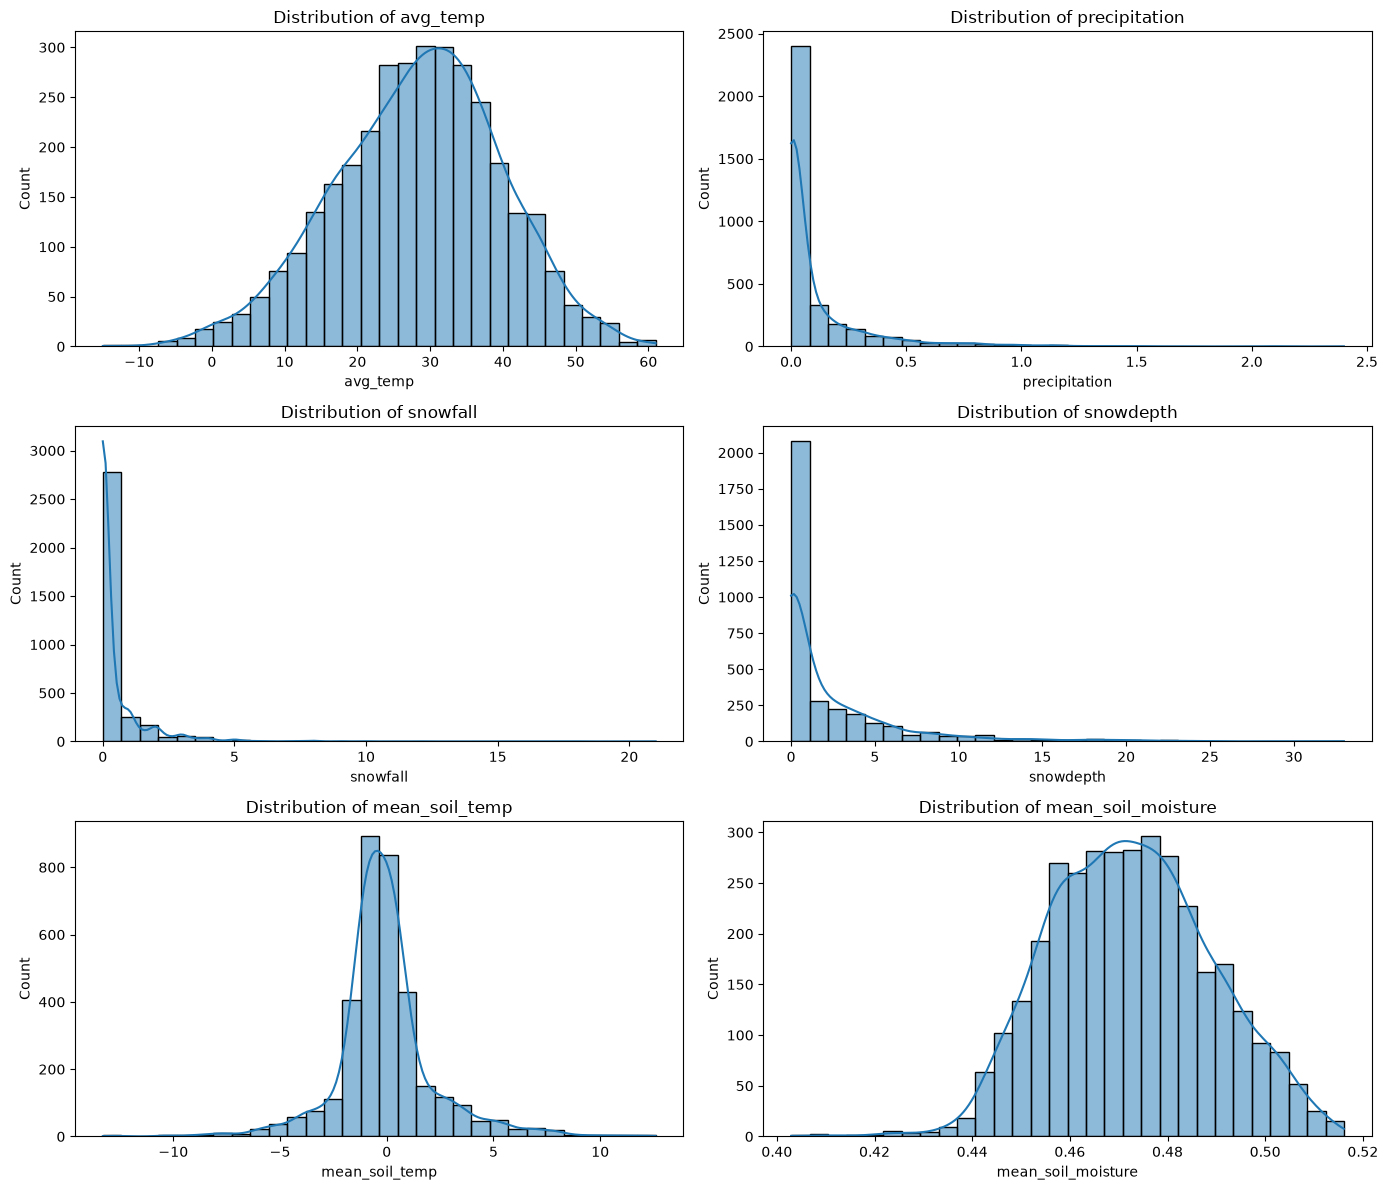

In [15]:
fig, axes = plt.subplots(3, 2, figsize=(14, 12))

groups_to_plot = [
    "avg_temp",
    "precipitation",
    "snowfall",
    "snowdepth",
    "mean_soil_temp",
    "mean_soil_moisture"
]

for ax, group in zip(axes.flat, groups_to_plot):

    values = data[weather_columns[group]].to_numpy().flatten()
    values = values[~np.isnan(values)]

    sns.histplot(
        values,
        bins=30,
        kde=True,
        ax=ax
    )

    ax.set_title(f"Distribution of {group}")
    ax.set_xlabel(group)

plt.tight_layout()
plt.show()

**Distribution findings:**

- **Average air temperature (°F)** is roughly bell-shaped (median 29°F, range −15°F to 61°F) with very few outliers. It needs no transformation.
- **Precipitation, snowfall, and snow depth (inches)** are zero-inflated and strongly right-skewed. 49% of daily precipitation values, 71% of daily snowfall values, and 50% of daily snow depth values are exactly 0 (skewness 3.6, 5.9, and 3.0). Trace amounts were already converted to 0 when the samples were generated. A log transform (`log1p`) or aggregating these into monthly totals or day counts will likely work better than raw daily values.
- **Mean soil temperature (°C)** is centered just below 0°C, which is expected for frozen winter soil. Soil temperatures are stored in **Celsius** while air temperatures are in **Fahrenheit**, so these features are on different scales.
- **Mean soil moisture** sits in a very narrow range (0.40 to 0.52), which is a much smaller scale than every other variable.

Because the variables have very different units and ranges, scaling (for example, `StandardScaler`) will be needed for scale-sensitive models such as logistic regression, SVMs, and k-NN.

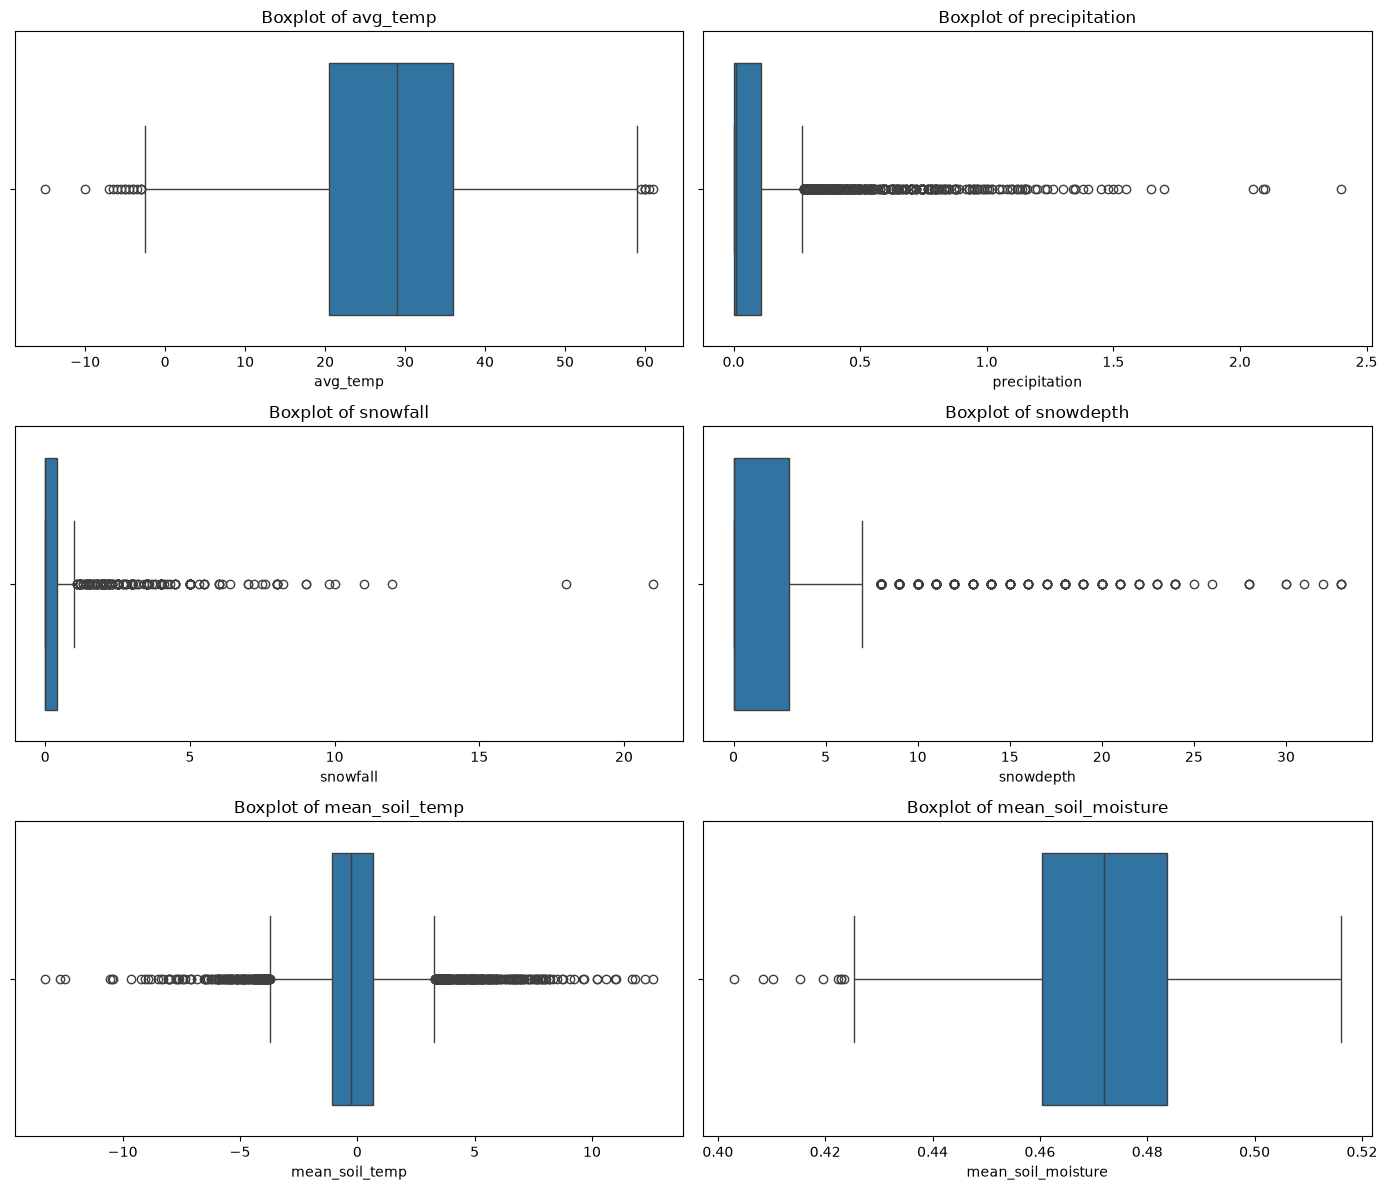

In [16]:
fig, axes = plt.subplots(3, 2, figsize=(14, 12))

for ax, group in zip(axes.flat, groups_to_plot):

    values = data[weather_columns[group]].to_numpy().flatten()
    values = values[~np.isnan(values)]

    sns.boxplot(x=values, ax=ax)

    ax.set_title(f"Boxplot of {group}")
    ax.set_xlabel(group)

plt.tight_layout()
plt.show()

The boxplots confirm what the histograms showed. Precipitation, snowfall, and snow depth have many points flagged as "outliers" (9–13% of values). These are not errors. They are real storm and heavy-snow days in a skewed distribution, so they should not be removed. Air temperature and soil moisture have almost no outliers. The soil temperature outliers (about 12%) come from the tight clustering of frozen-ground readings near 0°C, which makes ordinary warmer readings look extreme.

Since we have so many daily columns, the next step creates **monthly summary features**: January and February means for temperature, snow depth, and soil variables, and monthly totals for precipitation and snowfall. February 29 is excluded so every year is summarized the same way.

In [17]:
engineered = data[
    ["year", "phil_pred", "early_spring"]
].copy()

for group in weather_groups:

    for month in ["01", "02"]:

        cols = [
            col for col in weather_columns[group]
            if f"_{month}_" in col
            and not col.endswith("_02_29")
        ]

        if group in ["precipitation", "snowfall"]:

            engineered[f"{group}_{month}_total"] = (
                data[cols].sum(axis=1, min_count=1)
            )

        else:

            engineered[f"{group}_{month}_mean"] = (
                data[cols].mean(axis=1)
            )

display(engineered.head())

,year,phil_pred,early_spring,max_temp_01_mean,max_temp_02_mean,min_temp_01_mean,min_temp_02_mean,avg_temp_01_mean,avg_temp_02_mean,precipitation_01_total,...,min_soil_temp_01_mean,min_soil_temp_02_mean,max_soil_temp_01_mean,max_soil_temp_02_mean,mean_soil_moisture_01_mean,mean_soil_moisture_02_mean,min_soil_moisture_01_mean,min_soil_moisture_02_mean,max_soil_moisture_01_mean,max_soil_moisture_02_mean
0,1963,False,False,33.290323,32.785714,12.838710,7.571429,23.064516,20.178571,1.82,...,1.619355,0.325000,1.841935,0.414286,0.461156,0.471448,0.454742,0.468429,0.467226,0.476357
1,1982,False,True,30.838710,38.928571,10.966667,19.500000,20.833333,29.214286,4.65,...,-2.383871,-1.560714,-1.525806,-0.517857,0.478425,0.484580,0.472258,0.477857,0.484032,0.492179
2,1976,False,False,33.870968,47.892857,14.774194,22.607143,24.322581,35.250000,4.16,...,-0.867742,1.025000,-0.467742,3.096429,0.470484,0.468366,0.464645,0.452500,0.478968,0.484214
3,2006,False,False,46.548387,38.461538,28.806452,21.407407,37.677419,29.320000,4.15,...,1.245161,-0.132143,3.616129,1.360714,0.481090,0.467842,0.468903,0.463500,0.493903,0.473821
4,1953,False,True,42.967742,43.071429,25.580645,23.821429,34.274194,33.446429,3.20,...,0.261290,0.142857,1.661290,1.510714,0.482245,0.479638,0.472839,0.471036,0.493516,0.488500


## Compare Weather Features Between Classes

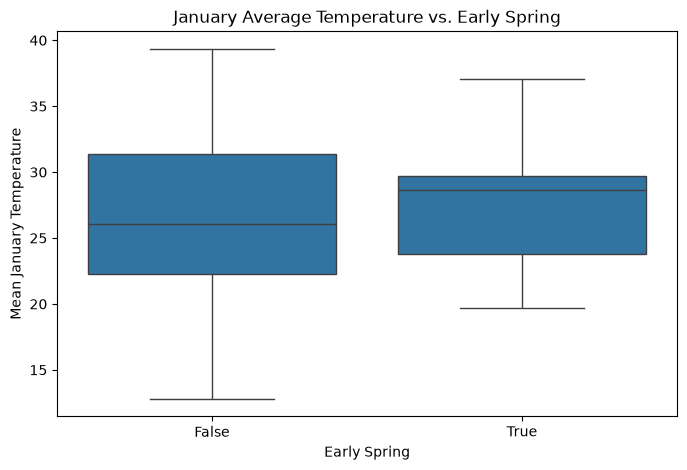

In [18]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=engineered,
    x="early_spring",
    y="avg_temp_01_mean"
)

plt.title("January Average Temperature vs. Early Spring")
plt.xlabel("Early Spring")
plt.ylabel("Mean January Temperature")

plt.show()

Early-spring years had a slightly warmer January on average (median 28.7°F vs. 26.1°F), but the boxes overlap heavily. January temperature on its own does not clearly separate the two classes.

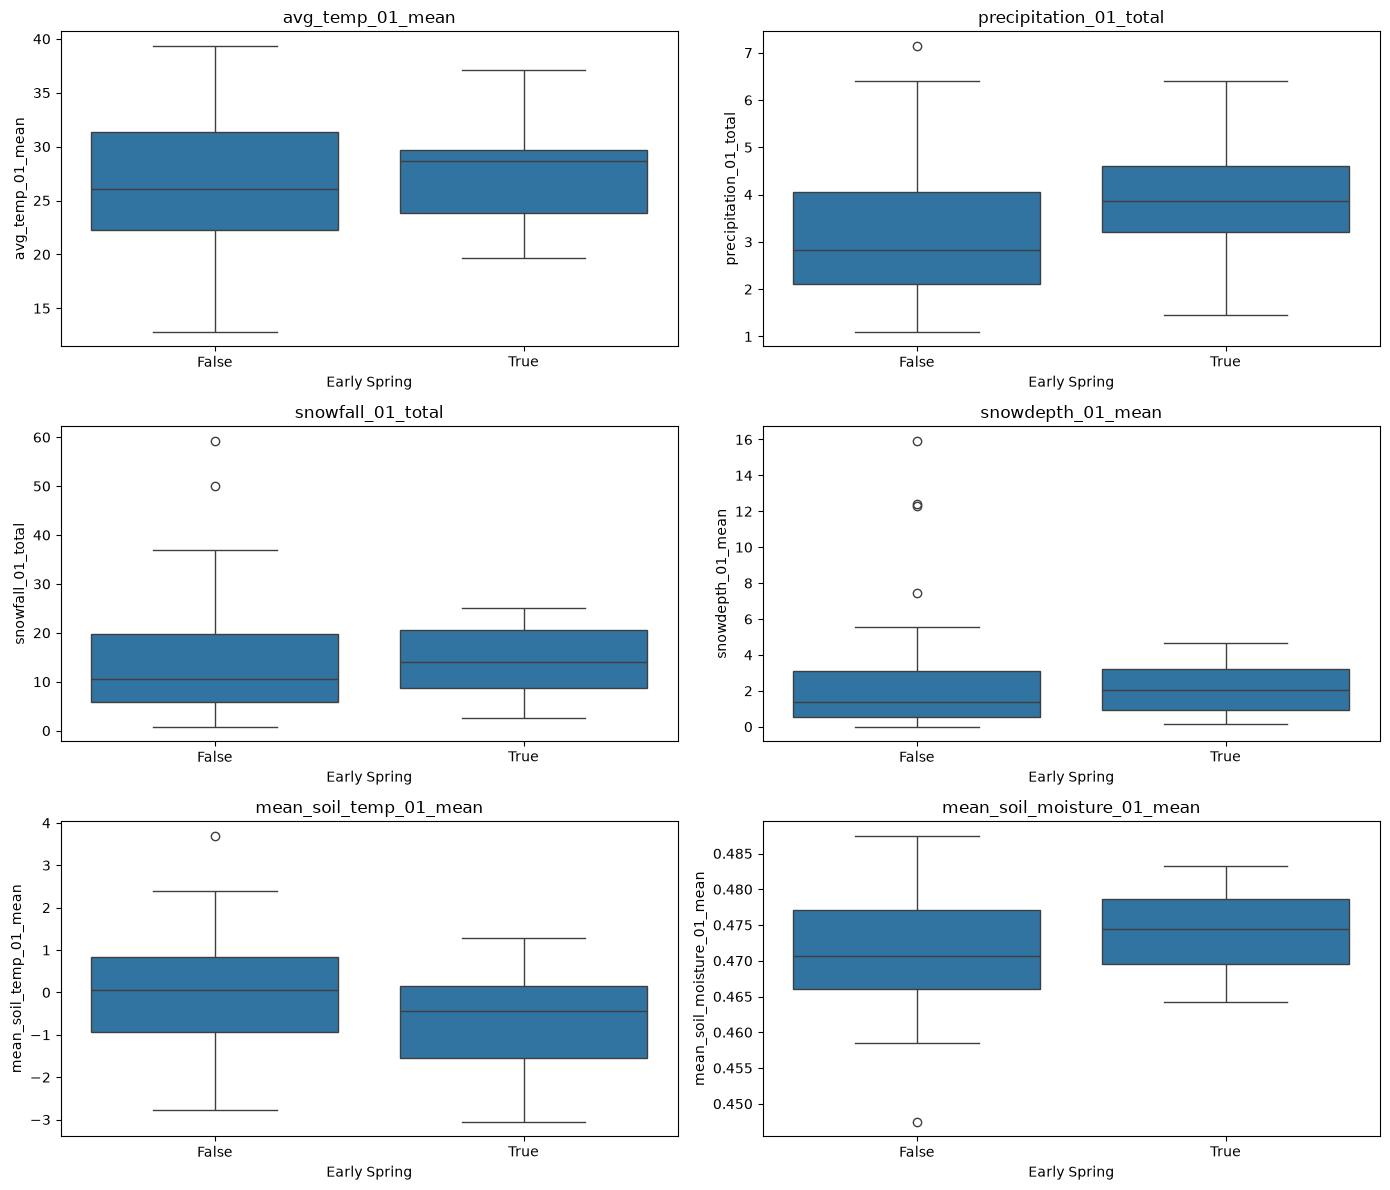

In [19]:
features_to_compare = [
    "avg_temp_01_mean",
    "precipitation_01_total",
    "snowfall_01_total",
    "snowdepth_01_mean",
    "mean_soil_temp_01_mean",
    "mean_soil_moisture_01_mean"
]

fig, axes = plt.subplots(3, 2, figsize=(14, 12))

for ax, feature in zip(axes.flat, features_to_compare):

    sns.boxplot(
        data=engineered,
        x="early_spring",
        y=feature,
        ax=ax
    )

    ax.set_title(feature)
    ax.set_xlabel("Early Spring")

plt.tight_layout()
plt.show()

None of the January summary features separate the classes cleanly. Early-spring years have somewhat higher January precipitation (median 3.9 vs. 2.8 inches) and slightly more January snowfall and snow depth, but the distributions overlap almost completely. Soil moisture looks nearly identical between the classes.

This suggests that no single January feature will be a strong predictor. Any signal will likely come from combinations of features or from February data, which is closer to the prediction date.

## Correlation Analysis

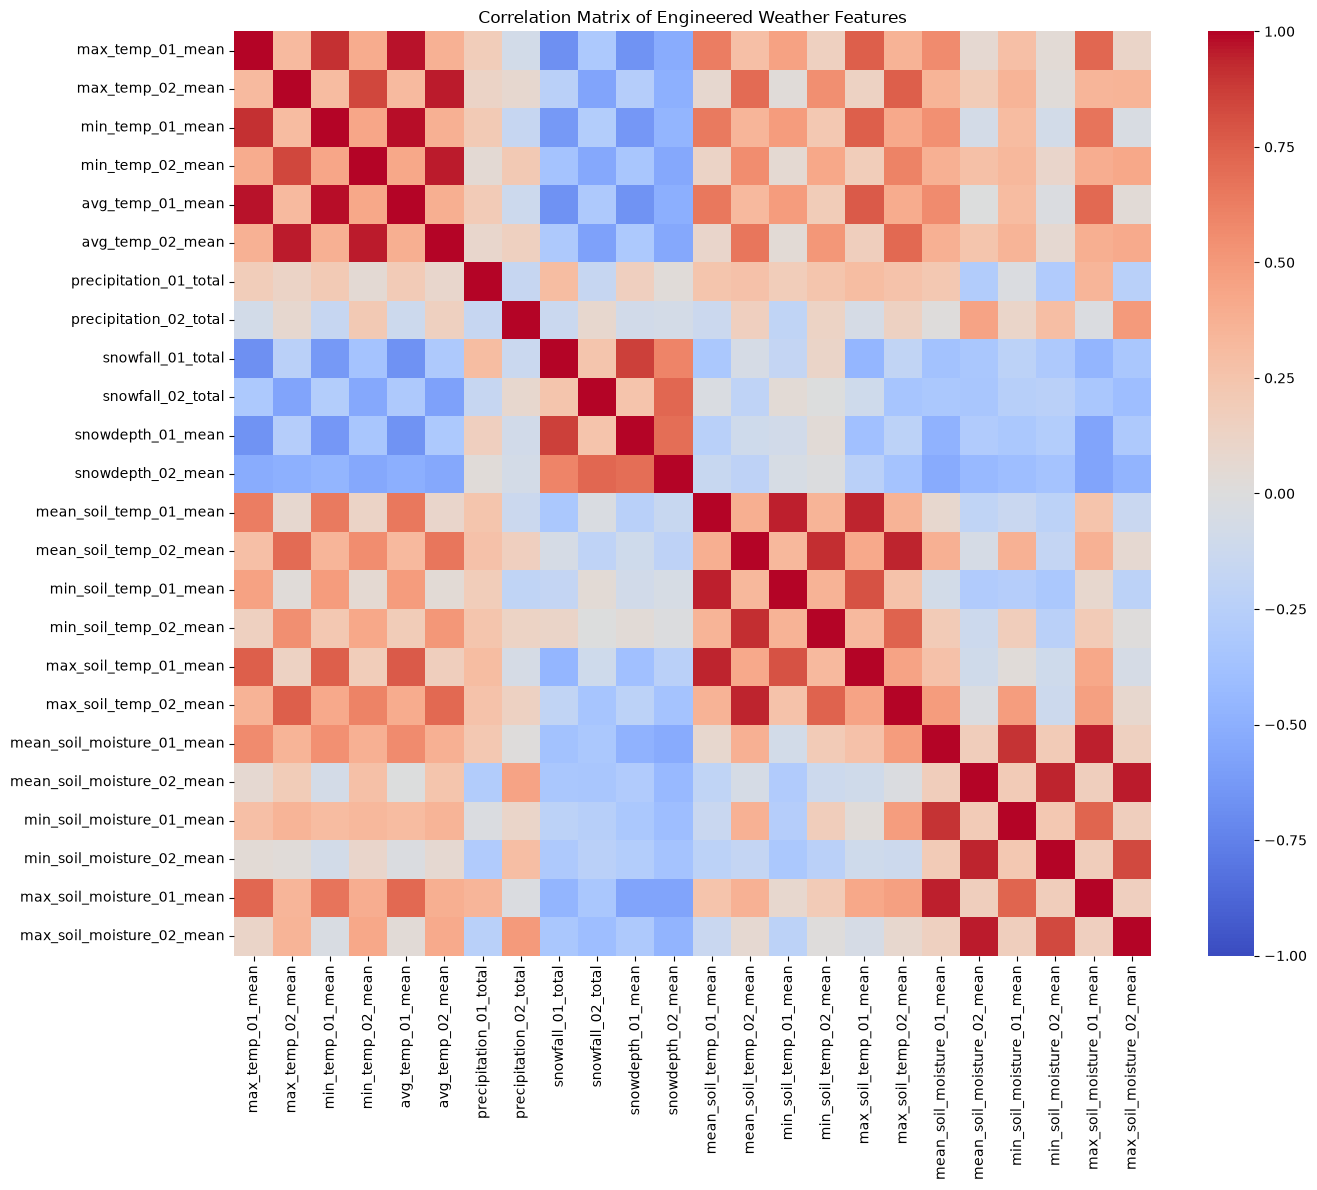

In [20]:
correlation_features = [
    col for col in engineered.columns
    if col not in ["year", "phil_pred", "early_spring"]
]

corr_matrix = engineered[correlation_features].corr()

plt.figure(figsize=(14, 12))

sns.heatmap(
    corr_matrix,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1
)

plt.title("Correlation Matrix of Engineered Weather Features")

plt.tight_layout()
plt.show()

The heatmap shows strong blocks of correlation **within** each variable family. Max, min, and average air temperatures move together, as do the mean, min, and max soil measurements. Correlations **between** families (for example, soil moisture vs. air temperature) are much weaker.

## Identify Strong Correlations between Feature Pairs

In [21]:
upper_triangle = corr_matrix.where(
    np.triu(
        np.ones(corr_matrix.shape),
        k=1
    ).astype(bool)
)

strong_correlations = (
    upper_triangle.stack()
    .reset_index()
)

strong_correlations.columns = [
    "Feature 1",
    "Feature 2",
    "Correlation"
]

strong_correlations["Absolute Correlation"] = (
    strong_correlations["Correlation"].abs()
)

strong_correlations = strong_correlations[
    strong_correlations["Absolute Correlation"] > 0.85
].sort_values(
    "Absolute Correlation",
    ascending=False
)

display(strong_correlations)

,Feature 1,Feature 2,Correlation,Absolute Correlation
52,min_temp_01_mean,avg_temp_01_mean,0.977085,0.977085
4,max_temp_01_mean,avg_temp_01_mean,0.976544,0.976544
479,mean_soil_moisture_02_mean,max_soil_moisture_02_mean,0.960912,0.960912
29,max_temp_02_mean,avg_temp_02_mean,0.959512,0.959512
77,min_temp_02_mean,avg_temp_02_mean,0.956619,0.956619
302,mean_soil_temp_01_mean,min_soil_temp_01_mean,0.952395,0.952395
454,mean_soil_moisture_01_mean,max_soil_moisture_01_mean,0.949828,0.949828
329,mean_soil_temp_02_mean,max_soil_temp_02_mean,0.944619,0.944619
477,mean_soil_moisture_02_mean,min_soil_moisture_02_mean,0.942970,0.942970
304,mean_soil_temp_01_mean,max_soil_temp_01_mean,0.942454,0.942454


14 pairs of engineered features have an absolute correlation above 0.85. All of them are either different summaries of the same measurement (for example, `min_temp_01_mean` and `avg_temp_01_mean`, r = 0.98) or snowfall vs. snow depth in January (r = 0.86). Keeping all of these adds redundant information, which matters most for linear models. We could keep just one per family (for example, only the average), or rely on regularization or PCA.

For comparison, only 575 of the roughly 545,000 pairs of **raw daily** features have a correlation above 0.85. Day-to-day weather is noisy, so the daily columns are not very redundant with each other, but each individual day is also unlikely to be very informative. That supports aggregating them.

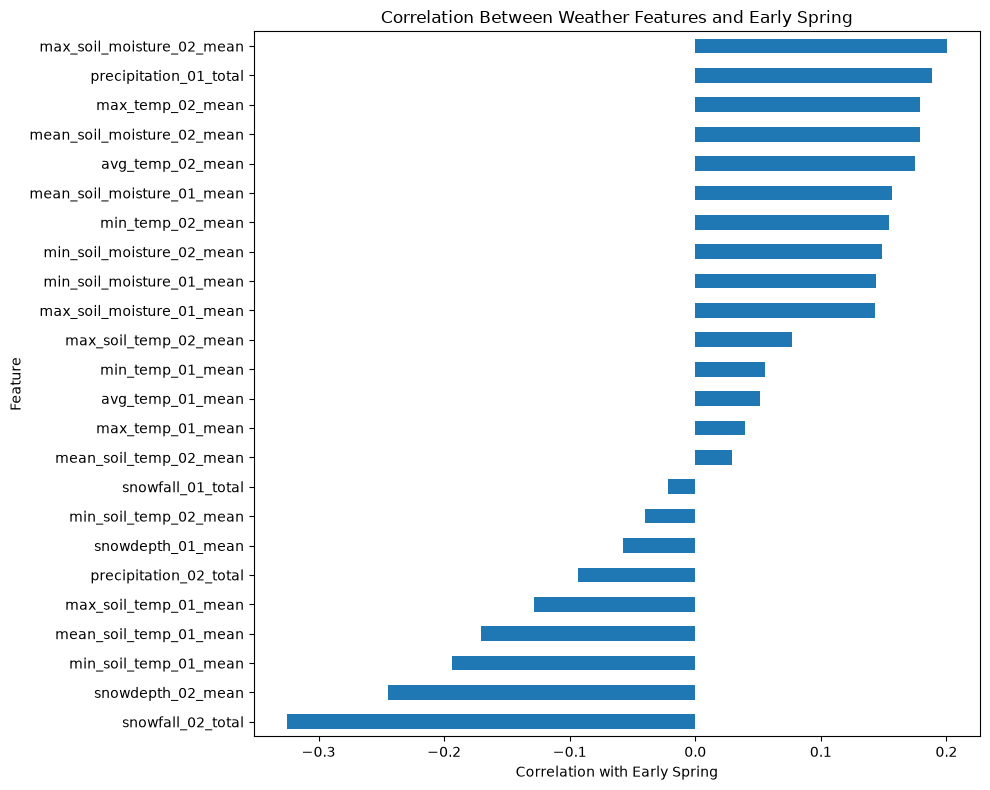

In [22]:
target_correlations = (
    engineered
    .drop(columns=["year", "phil_pred"])
    .assign(
        early_spring=engineered["early_spring"].astype(int)
    )
    .corr()["early_spring"]
    .drop("early_spring")
    .sort_values()
)

plt.figure(figsize=(10, 8))

target_correlations.plot(kind="barh")

plt.title("Correlation Between Weather Features and Early Spring")
plt.xlabel("Correlation with Early Spring")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

All correlations with the target are weak. The strongest are:

- `snowfall_02_total` (r = −0.33): years with more February snow were less likely to have an early spring.
- `snowdepth_02_mean` (r = −0.24)
- `max_soil_moisture_02_mean` (r = 0.20) and `precipitation_01_total` (r = 0.19)

`year` itself (r = 0.24) is as strong as any weather feature (see the Historical Trends section). With only 57 observations, a correlation needs to be about ±0.26 to be statistically distinguishable from zero, so only February snowfall clearly clears that bar. **February features were generally more correlated with the target than January features**, which makes sense because February is closer to the planting window. These are linear correlations only, and tree-based models may find non-linear relationships.

## Phil's Prediction

In [23]:
phil_table = pd.crosstab(
    data["phil_pred"],
    data["early_spring"]
)

phil_table

early_spring,False,True
phil_pred,,
False,37,10
True,6,4


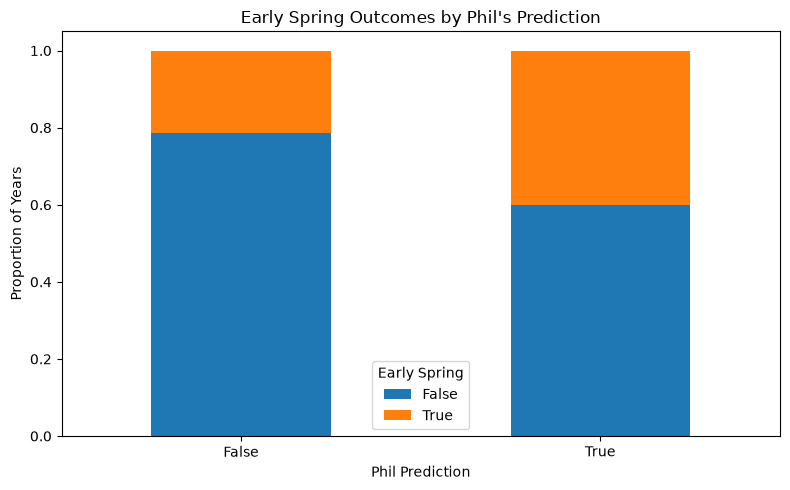

In [24]:
phil_proportions = pd.crosstab(
    data["phil_pred"],
    data["early_spring"],
    normalize="index"
)

phil_proportions.plot(
    kind="bar",
    stacked=True,
    figsize=(8, 5)
)

plt.title("Early Spring Outcomes by Phil's Prediction")
plt.xlabel("Phil Prediction")
plt.ylabel("Proportion of Years")
plt.legend(title="Early Spring")

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Phil predicted an early spring in only 10 of the 57 training years. When he predicted an early spring (`phil_pred = True`), 4 of 10 years (40%) actually met the planting criteria. When he predicted six more weeks of winter, 10 of 47 years (21%) did. That direction is consistent with Phil having a small amount of signal, but 10 "True" predictions is far too few to draw a confident conclusion. Phil's prediction will stay in as a candidate feature, and cross-validation will show whether it helps.

Note: Phil's prediction is about mid-March, while our target is May 1–10 planting conditions, so even a perfect groundhog would not be a perfect predictor here.

## Explore Climate Features

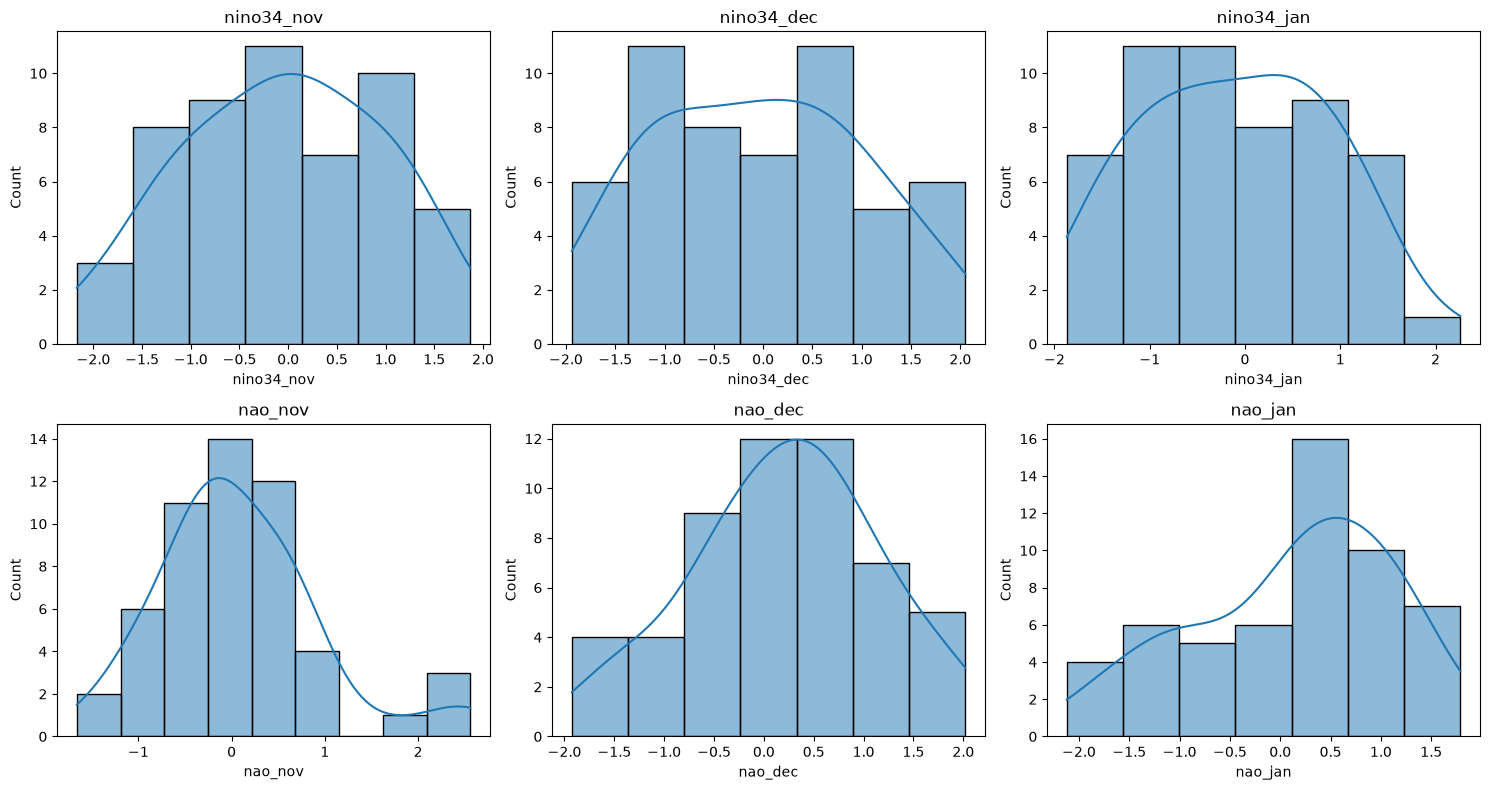

In [25]:
climate_features = [
    "nino34_nov",
    "nino34_dec",
    "nino34_jan",
    "nao_nov",
    "nao_dec",
    "nao_jan"
]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))

for ax, feature in zip(axes.flat, climate_features):

    sns.histplot(
        data=data,
        x=feature,
        kde=True,
        ax=ax
    )

    ax.set_title(feature)

plt.tight_layout()
plt.show()

All six climate index features are roughly symmetric and centered near 0, which is expected for anomaly indices. `nao_nov` is the only one with noticeable right skew (skewness 0.94). The values are already on a similar standardized scale. Each index is missing for 3 or 4 training years (1947–1950) because the NOAA records start in 1950, so this missingness is structural rather than random.

## Climate Indices compared to Spring Outcomes

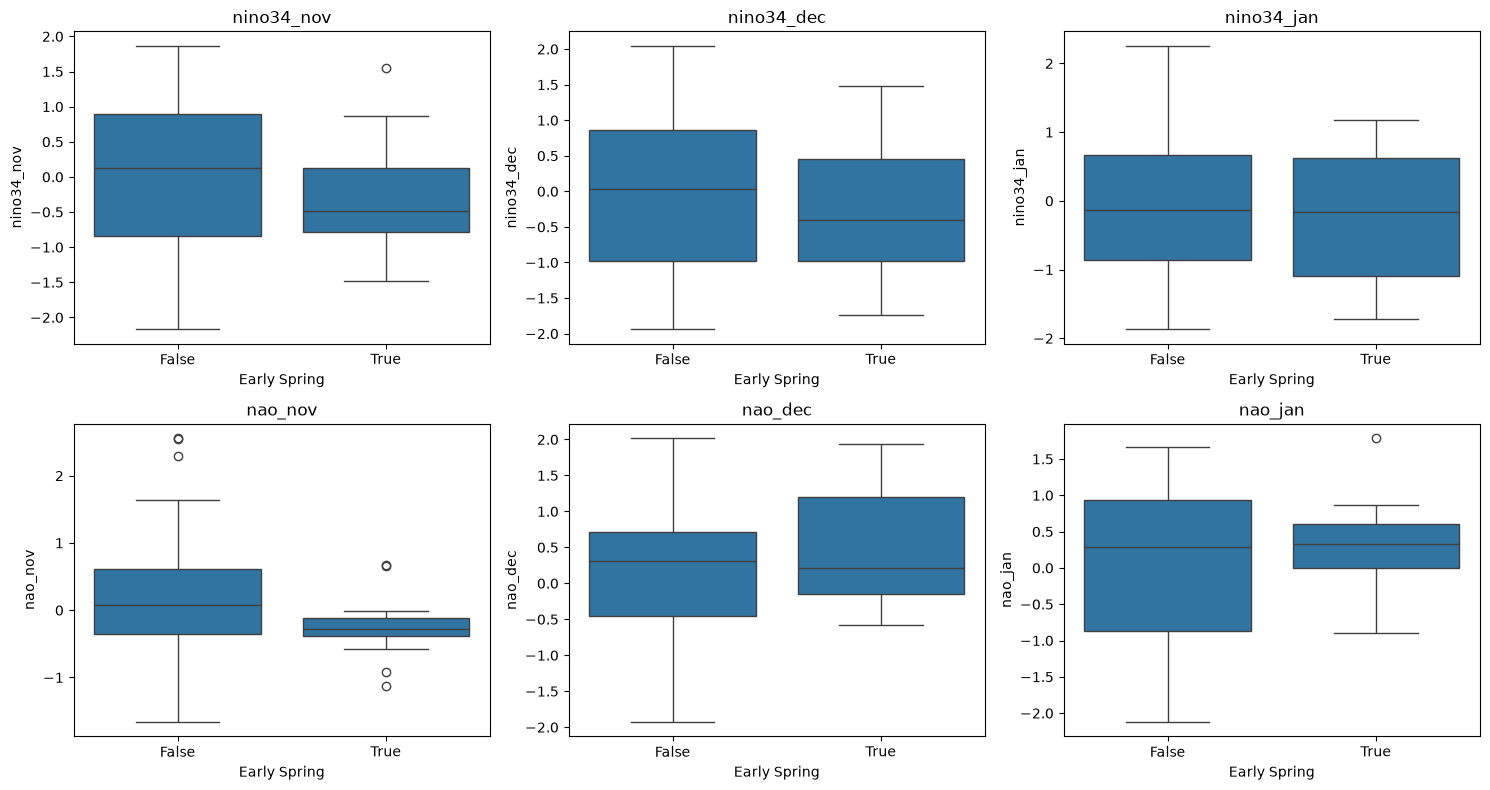

In [26]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))

for ax, feature in zip(axes.flat, climate_features):

    sns.boxplot(
        data=data,
        x="early_spring",
        y=feature,
        ax=ax
    )

    ax.set_title(feature)
    ax.set_xlabel("Early Spring")

plt.tight_layout()
plt.show()

Early-spring years tended to have lower (more La Niña-like) Niño 3.4 values in November and December (median −0.49 vs. 0.13 in November) and a lower November NAO (median −0.28 vs. 0.08). However, the classes overlap substantially, and the correlations with the target are weak (|r| between 0.08 and 0.21). These features may still add information when combined with the local weather features.

## Climate Index Correlations

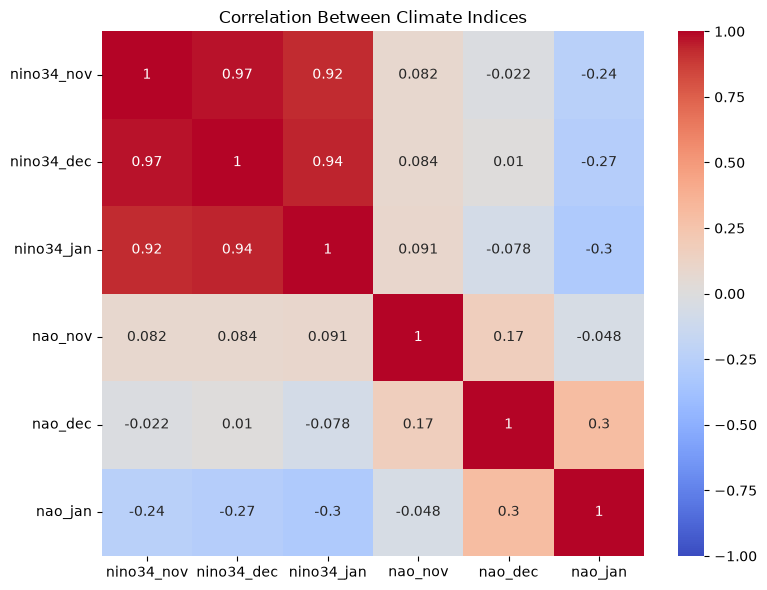

In [27]:
climate_corr = data[climate_features].corr()

plt.figure(figsize=(8, 6))

sns.heatmap(
    climate_corr,
    annot=True,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1
)

plt.title("Correlation Between Climate Indices")
plt.tight_layout()
plt.show()

The three Niño 3.4 features are almost perfectly correlated with each other (r = 0.92 to 0.97) because ENSO conditions change slowly from month to month. One Niño 3.4 value (or their average) likely carries nearly all of the information. The NAO features are only weakly correlated with each other (r ≤ 0.30) because the NAO changes month to month, so each month may contribute different information. Niño 3.4 and NAO are nearly unrelated to each other, except for a mild negative correlation between January NAO and Niño 3.4 (about −0.3).

## Historical Trends

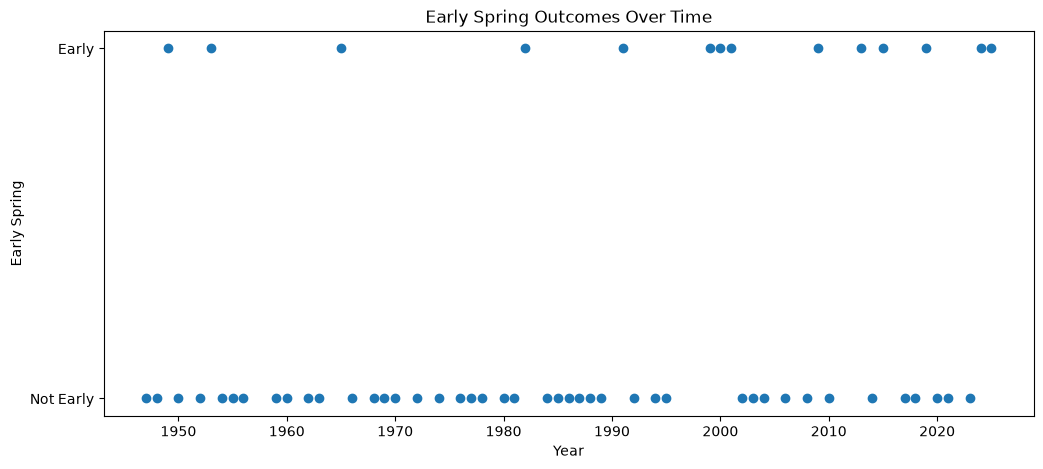

In [28]:
yearly_data = data.sort_values("year").copy()

yearly_data["early_spring_numeric"] = (
    yearly_data["early_spring"].astype(int)
)

plt.figure(figsize=(12, 5))

plt.scatter(
    yearly_data["year"],
    yearly_data["early_spring_numeric"]
)

plt.yticks([0, 1], ["Not Early", "Early"])

plt.title("Early Spring Outcomes Over Time")
plt.xlabel("Year")
plt.ylabel("Early Spring")

plt.show()

Next from this we will look at frequency by decade.

In [29]:
yearly_data["decade"] = (
    yearly_data["year"] // 10
) * 10

decade_summary = yearly_data.groupby("decade").agg(
    total_years=("early_spring", "count"),
    early_springs=("early_spring", "sum"),
    early_spring_rate=("early_spring", "mean")
)

display(decade_summary)

,total_years,early_springs,early_spring_rate
decade,,,
1940,3,1,0.333333
1950,7,1,0.142857
1960,7,1,0.142857
1970,6,0,0.000000
1980,9,1,0.111111
1990,5,2,0.400000
2000,8,3,0.375000
2010,7,3,0.428571
2020,5,2,0.400000


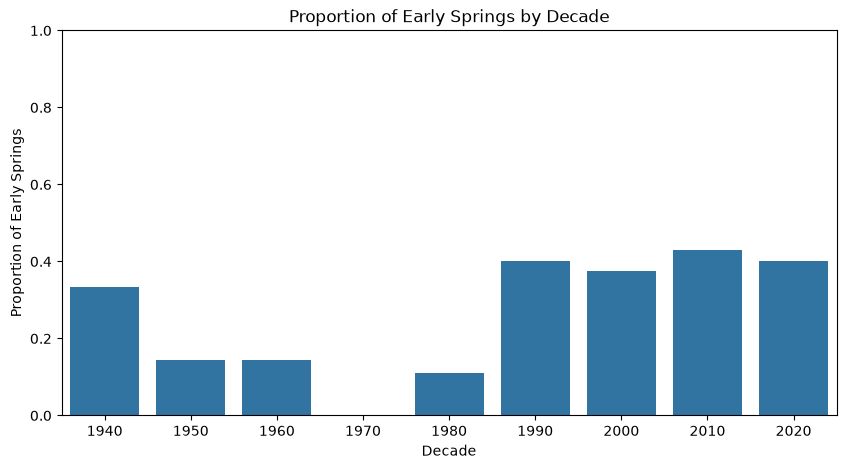

In [30]:
plt.figure(figsize=(10, 5))

sns.barplot(
    x=decade_summary.index,
    y=decade_summary["early_spring_rate"]
)

plt.title("Proportion of Early Springs by Decade")
plt.xlabel("Decade")
plt.ylabel("Proportion of Early Springs")

plt.ylim(0, 1)
plt.show()

The early-spring rate has clearly increased over time. Before 1990, only 4 of 32 training years (12.5%) were early springs. From 1990 on, 10 of 25 years (40%) were. This could reflect a warming climate trend.

This has two implications:
1. `year` may be a useful predictor in its own right, since it captures the long-term trend.
2. Our train/test split was a random stratified split, so the training data includes years both before and after the test years. For a model meant to forecast **future** years, we should also consider time-based validation (for example, training on earlier years and validating on later ones) to see if performance holds up.

Some decades have only 3 to 9 training years, so the per-decade rates are noisy.

### Additional Feature Engineering

Next we create January features that capture weather patterns rather than just averages: temperature variability, temperature extremes, the number of days above freezing, and the number of snowy days.

In [31]:
jan_snow_cols = [
    col for col in weather_columns["snowfall"]
    if "_01_" in col
]

engineered["jan_snowy_days"] = (
    data[jan_snow_cols] > 0
).sum(axis=1)

display(
    engineered[
        ["year", "jan_snowy_days"]
    ].head()
)

,year,jan_snowy_days
0,1963,5
1,1982,15
2,1976,19
3,2006,5
4,1953,6


In [32]:
jan_avg_temp_cols = [
    col for col in weather_columns["avg_temp"]
    if "_01_" in col
]

engineered["jan_temp_std"] = data[jan_avg_temp_cols].std(axis=1)
engineered["jan_temp_min"] = data[jan_avg_temp_cols].min(axis=1)
engineered["jan_temp_max"] = data[jan_avg_temp_cols].max(axis=1)

display(
    engineered[
        ["year", "jan_temp_std", "jan_temp_min", "jan_temp_max"]
    ].head()
)

,year,jan_temp_std,jan_temp_min,jan_temp_max
0,1963,11.886086,-5.0,41.0
1,1982,12.566604,-6.5,42.5
2,1976,10.142771,4.5,46.0
3,2006,7.229048,25.0,53.0
4,1953,7.439577,19.5,45.5


In [33]:
engineered["jan_days_above_freezing"] = (
    data[jan_avg_temp_cols] > 32
).sum(axis=1)

display(
    engineered[
        ["year", "jan_days_above_freezing"]
    ].head()
)

,year,jan_days_above_freezing
0,1963,8
1,1982,5
2,1976,8
3,2006,23
4,1953,21


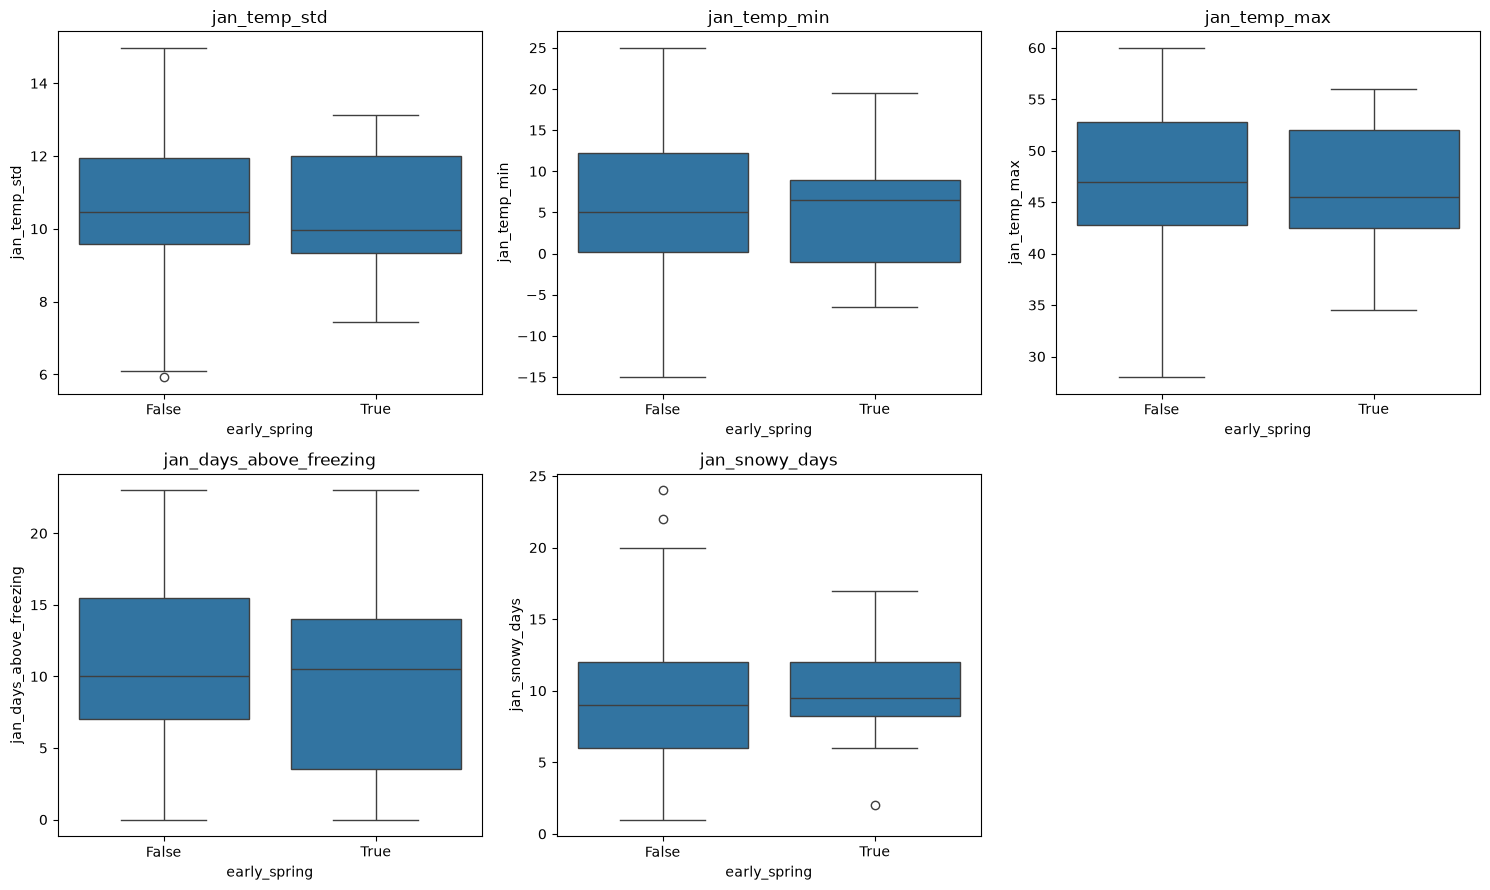

In [34]:
additional_features = [
    "jan_temp_std",
    "jan_temp_min",
    "jan_temp_max",
    "jan_days_above_freezing",
    "jan_snowy_days"
]

fig, axes = plt.subplots(2, 3, figsize=(15, 9))

for ax, feature in zip(axes.flat, additional_features):

    sns.boxplot(
        data=engineered,
        x="early_spring",
        y=feature,
        ax=ax
    )

    ax.set_title(feature)

axes.flat[-1].axis("off")

plt.tight_layout()
plt.show()

None of the additional January features show a meaningful difference between the classes. The medians are nearly identical: 10.5 vs. 10 days above freezing, 9.5 vs. 9 snowy days, and a temperature standard deviation of 10.0 vs. 10.5°F. These features did not add much signal, though they may still help in combination with others.

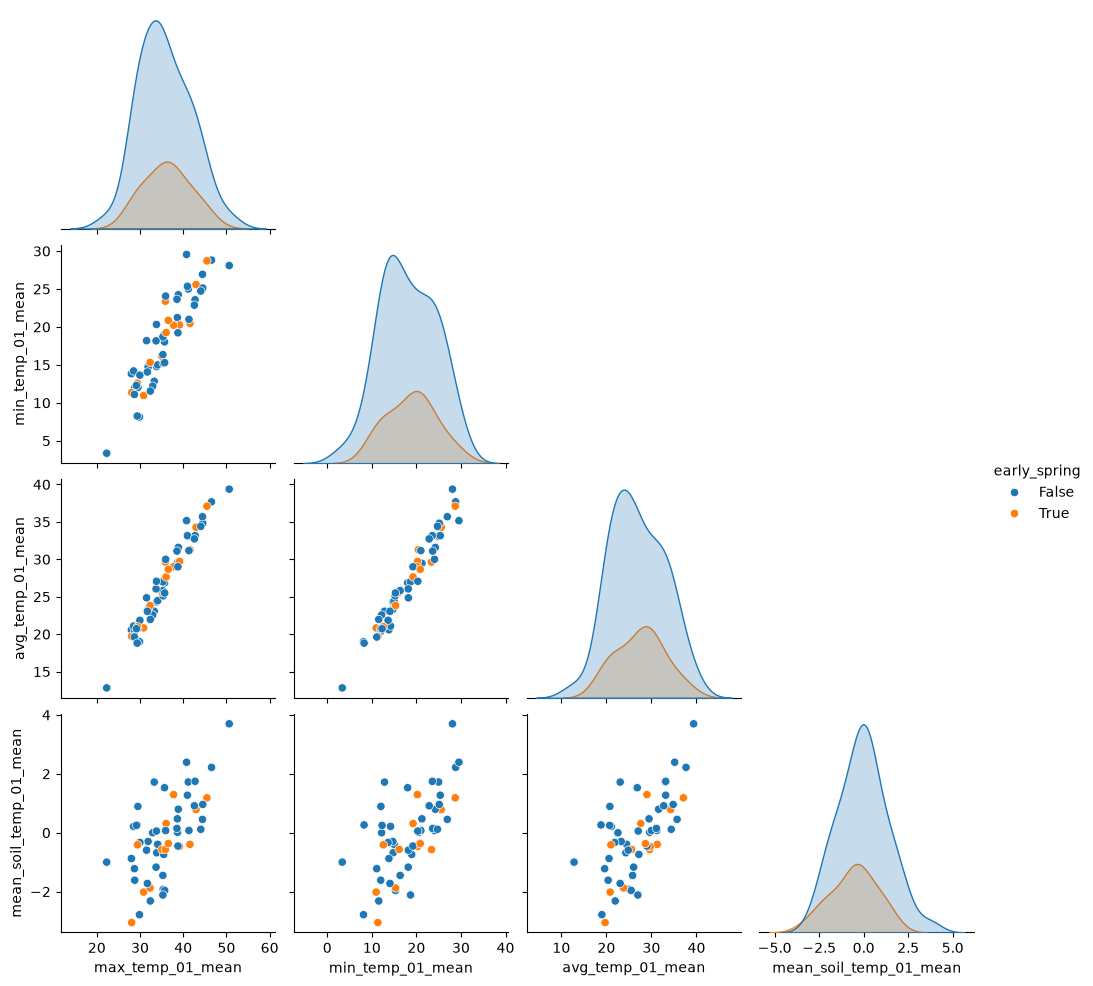

In [35]:
temperature_features = [
    "max_temp_01_mean",
    "min_temp_01_mean",
    "avg_temp_01_mean",
    "mean_soil_temp_01_mean"
]

sns.pairplot(
    engineered,
    vars=temperature_features,
    hue="early_spring",
    corner=True
)

plt.show()

The pairplot shows that the four January temperature features are strongly linearly related to each other. The early-spring and non-early-spring points are thoroughly mixed in every panel, with no region where one class dominates. This confirms that January temperature alone, or a simple combination of January temperatures, will not separate the classes.

In [36]:
coverage = pd.DataFrame({
    "year": data["year"]
})

for group in weather_groups:

    jan_cols = [
        col for col in weather_columns[group]
        if "_01_" in col
    ]

    coverage[f"{group}_jan_coverage"] = (
        data[jan_cols].notna().mean(axis=1)
    )

display(coverage.head())

,year,max_temp_jan_coverage,min_temp_jan_coverage,avg_temp_jan_coverage,precipitation_jan_coverage,snowfall_jan_coverage,snowdepth_jan_coverage,mean_soil_temp_jan_coverage,min_soil_temp_jan_coverage,max_soil_temp_jan_coverage,mean_soil_moisture_jan_coverage,min_soil_moisture_jan_coverage,max_soil_moisture_jan_coverage
0,1963,1.0,1.000000,1.000000,1.0,1.000000,1.0,1.0,1.0,1.0,1.0,1.0,1.0
1,1982,1.0,0.967742,0.967742,1.0,0.967742,1.0,1.0,1.0,1.0,1.0,1.0,1.0
2,1976,1.0,1.000000,1.000000,1.0,1.000000,1.0,1.0,1.0,1.0,1.0,1.0,1.0
3,2006,1.0,1.000000,1.000000,1.0,1.000000,1.0,1.0,1.0,1.0,1.0,1.0,1.0
4,1953,1.0,1.000000,1.000000,1.0,1.000000,1.0,1.0,1.0,1.0,1.0,1.0,1.0


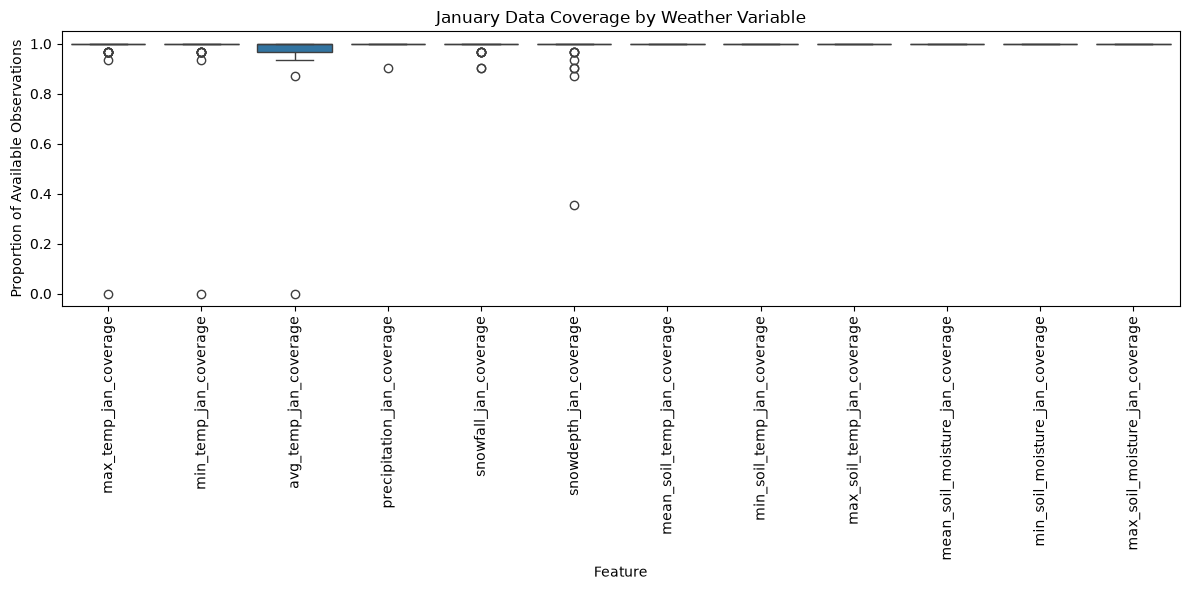

In [37]:
coverage_long = coverage.melt(
    id_vars="year",
    var_name="Feature",
    value_name="Coverage"
)

plt.figure(figsize=(12, 6))

sns.boxplot(
    data=coverage_long,
    x="Feature",
    y="Coverage"
)

plt.xticks(rotation=90)
plt.title("January Data Coverage by Weather Variable")
plt.ylabel("Proportion of Available Observations")

plt.tight_layout()
plt.show()

January coverage is essentially complete for the soil variables in every year, and close to complete for most weather variables. The low outliers come from a few specific years. **2001 is missing all January air temperatures**, and 1947 is missing most of its January snow depth. (In February, 2004 is missing all of its air temperatures.) These years should be imputed carefully. Also, the count-based features (`jan_days_above_freezing`, `jan_snowy_days`) currently treat a missing day as "not above freezing" / "no snow", so 2001 incorrectly shows 0 days above freezing. This should be fixed in the Preparation notebook, for example by computing the count as a proportion of non-missing days.

In [38]:
import re

daily_features = [
    col for col in data.columns
    if re.search(r"_\d{2}_\d{2}$", col)
]

potential_future_features = [
    col for col in daily_features
    if (
        int(col[-5:-3]) > 2
        or (
            int(col[-5:-3]) == 2
            and int(col[-2:]) > 2
        )
    )
]

print("Total daily features:", len(daily_features))

print(
    "Features after February 2:",
    len(potential_future_features)
)

display(potential_future_features[:20])

Total daily features: 732
Features after February 2: 336


['max_temp_02_03',
 'max_temp_02_04',
 'max_temp_02_05',
 'max_temp_02_06',
 'max_temp_02_07',
 'max_temp_02_08',
 'max_temp_02_09',
 'max_temp_02_10',
 'max_temp_02_11',
 'max_temp_02_12',
 'max_temp_02_13',
 'max_temp_02_14',
 'max_temp_02_15',
 'max_temp_02_16',
 'max_temp_02_17',
 'max_temp_02_18',
 'max_temp_02_19',
 'max_temp_02_20',
 'max_temp_02_21',
 'max_temp_02_22']

In Frame the Problem we established that the prediction must be available by **March 1**, when farms order their seeds. Every daily feature runs from January 1 through March 1, and the climate indices only use November through January (February values are not published until after March 1). **So none of the current features leak future information.**

This cell shows how many features would be lost if the client wanted the prediction on February 2 (Groundhog Day) instead: 336 of the 732 daily features. Since February features showed the strongest correlations with the target, an earlier deadline would likely hurt performance.

## Compare Year Distributions

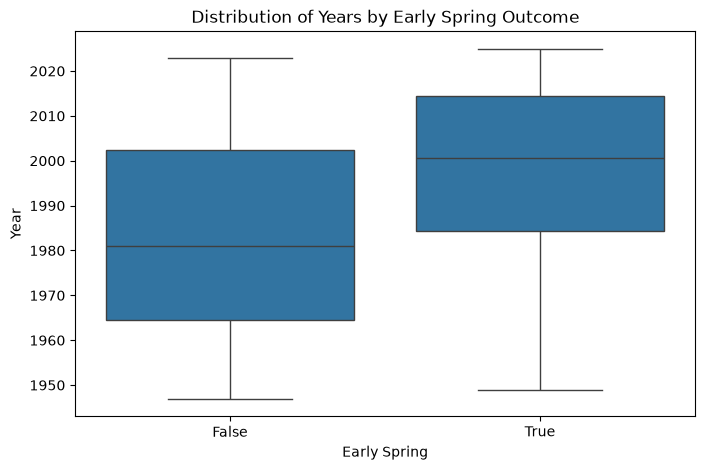

In [39]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=data,
    x="early_spring",
    y="year"
)

plt.title("Distribution of Years by Early Spring Outcome")
plt.xlabel("Early Spring")
plt.ylabel("Year")

plt.show()

Early-spring years are concentrated in more recent decades (median year 2000 vs. 1981 for non-early springs). This matches the decade analysis and reinforces that `year` carries real signal.

In [40]:
original_features = data.shape[1] - 1

engineered_features = engineered.shape[1] - 1

print("Original feature count:", original_features)

print("Engineered feature count:", engineered_features)

print(
    "Reduction:",
    original_features - engineered_features
)

print(
    "Percentage reduction:",
    round(
        (1 - engineered_features / original_features) * 100,
        2
    ),
    "%"
)

Original feature count: 740
Engineered feature count: 31
Reduction: 709
Percentage reduction: 95.81 %


Monthly aggregation plus the extra January features reduces the predictor count from 740 to 31, a 95.8% reduction. This brings the ratio of features to observations much closer to something a model can learn from without memorizing the training data. These 31 features include `year` and `phil_pred`.

In [41]:
print("Total observations:", len(data))

print(
    "Early spring observations:",
    data["early_spring"].sum()
)

print(
    "Non-early spring observations:",
    (~data["early_spring"]).sum()
)

Total observations: 57
Early spring observations: 14
Non-early spring observations: 43


This confirms the class counts from earlier: 14 early-spring years and 43 non-early-spring years.

## Data Quality Checks

In [42]:
numeric_features = data.select_dtypes(
    include=["number"]
)

infinite_counts = np.isinf(
    numeric_features.to_numpy()
).sum()

print("Infinite values:", infinite_counts)

Infinite values: 0


No infinite values were found, so no special handling is needed beyond missing values.

In [43]:
print(
    "Missing target values:",
    data["early_spring"].isna().sum()
)

Missing target values: 0


There are no missing target values, so every training year can be used.

In [44]:
print(
    "Duplicate years:",
    data["year"].duplicated().sum()
)

Duplicate years: 0


### Data Quality Findings

There are no infinite values, no missing target values, and no duplicate years. Combined with the earlier checks (no duplicate rows and no constant features), the data is clean apart from the missing values discussed above.

## Attribute Summary

| Attribute group | Count | Type | Units / range | Missing | Notes |
|---|---|---|---|---|---|
| `year` | 1 | int, unbounded | 1947–2025 | 0% | Captures the long-term trend |
| `phil_pred` | 1 | Boolean | True / False | 0% | Only 10 of 57 years are True |
| Air temperature (max/min/avg) | 183 | float | °F | Mostly < 5%; 2001 is missing all January temps and 2004 all February temps | Roughly normal |
| Precipitation, snowfall | 122 | float, ≥ 0 | inches | < 2% | Zero-inflated, right-skewed; trace values set to 0 |
| Snow depth | 61 | float, ≥ 0 | inches | < 4%; 1947 missing most of January | Zero-inflated, right-skewed |
| Soil temperature (mean/min/max) | 183 | float | °C | Only Feb 29 | Different unit from air temperature |
| Soil moisture (mean/min/max) | 183 | float, bounded | 0.40–0.52 | Only Feb 29 | Very narrow range |
| Niño 3.4 (Nov, Dec, Jan) | 3 | float | anomaly, about −2 to 2 | 1947–1949/50 | Highly inter-correlated |
| NAO (Nov, Dec, Jan) | 3 | float | index, about −2 to 2.5 | 1947–1949/50 | Weakly inter-correlated |
| `early_spring` (target) | 1 | Boolean | True / False | 0% | 14 True / 43 False |

Every daily variable also has a `02_29` column that is missing in non-leap years.

## How Would We Solve This Manually?

A person trying to predict planting conditions by hand would:

1. Check how much snow fell in February and how much snow is still on the ground. Snowier Februaries were less likely to lead to an early spring.
2. Check whether late winter has been warmer than usual (February air temperatures were slightly higher in early-spring years).
3. Consider the recent trend. Early springs have been about three times more common since 1990.
4. Look at the ENSO and NAO conditions as background context.

No single rule from these would be very reliable, because the class distributions overlap so much. That is why a model combining many weak signals is needed.

## Additional Data That Could Be Useful

- **May 1–10 weather and soil records** to verify the `early_spring` labels against the client's four criteria. These would not be used as features because they are unavailable at prediction time.
- **NOAA seasonal outlooks** (for example, the Climate Prediction Center's spring temperature outlook, which is published before March 1). These could be valid forecasting features.


## Summary of Exploratory Data Analysis

### 1. High Dimensionality

The training set contains 57 observations and 740 predictors. Having far more features than observations creates a substantial risk of overfitting. Feature engineering, feature selection, and regularization should be investigated during preprocessing and model training.

### 2. Class Imbalance

The target contains 43 non-early-spring years and 14 early-spring years, so the majority-class baseline accuracy is about 75.44%. As decided in Frame the Problem, missing an early spring is the more costly error for the farms, so evaluation should emphasize **recall** for the early-spring class, along with precision and F1-score, rather than accuracy.

### 3. Missing Values

The dataset contains 894 missing values across 284 columns.

- **498 (56%)** come from the 12 February 29 columns, which are obviously missing in non-leap years. Dropping these columns gives every year the same representation.
- The climate indices are missing for 1947–1950 because the NOAA records start in 1950.
- The remaining missing values are mostly in the air temperature and snow measurements and are concentrated in a few years. **2001 is missing every January air temperature and 2004 every February air temperature**, so monthly summaries for those years will be missing and need imputation.

### 4. Duplicate and Constant Features

No duplicate rows, duplicate years, or constant features were found, so no features need to be removed for these reasons.

### 5. Feature Distributions

Precipitation, snowfall, and snow depth are zero-inflated and right-skewed. Air temperature is roughly normal. Soil temperature is in °C while air temperature is in °F, and soil moisture has a very narrow range. Scaling, and possibly log transforms for the precipitation-type variables, should be considered depending on the model.

### 6. Feature Correlations

Raw daily features are not highly redundant with each other, but they are individually noisy. Monthly summaries of the same measurement (max/min/avg temperature, mean/min/max soil) are highly correlated (r > 0.85), as are the three Niño 3.4 months (r > 0.9). Keeping one representative per family, regularization, or PCA may help, particularly for linear models.

### 7. Feature Engineering

Monthly averages and totals reduce the 740 predictors to 31 (a 95.8% reduction). Additional features such as temperature variability, days above freezing, and snowy days were created. The most promising engineered features so far are **February** snowfall, snow depth, and temperature. Their predictive value will be evaluated with cross-validation.

### 8. Climate Indices

Niño 3.4 and NAO show weak relationships with the target (|r| ≤ 0.21). They will be retained as candidate predictors, but the three Niño 3.4 months are nearly redundant.

### 9. Punxsutawney Phil

When Phil predicted an early spring, 40% of years met the planting criteria, compared with 21% when he did not. However, he predicted an early spring in only 10 training years, so this difference is not reliable. Phil's prediction will remain a candidate feature.

### 10. Temporal Considerations

The early-spring rate rose from 12.5% before 1990 to 40% from 1990 on, and `year` is as correlated with the target as any weather feature. `year` should be kept as a candidate feature, and time-based validation should be considered because the model will forecast future years.



# Conclusion

The exploratory analysis identified several challenges to address before model training.

The biggest issue is high dimensionality: 740 predictors but only 57 observations. Feature engineering, such as monthly aggregation (which reduces the feature count by about 96%), feature selection, and regularization will be important for generalization.

The target is imbalanced, with about 75% of years not having an early spring. Because missing an early spring is costly for the farms, evaluation should focus on recall, precision, and F1 rather than accuracy.

Most missing values are structural problems, February 29 in non-leap years, and climate indices before 1950. The rest are concentrated in a few years (notably 2001 and 2004) and will need imputation.

No single feature separates the classes well. The strongest signals are February snowfall and snow depth, late-winter temperature, and the long-term trend in `year`. Climate indices and Phil's prediction show weak relationships and will remain as candidate predictors.

All features are available by the March 1 prediction deadline.
